# The keystone and the closed form

Verification notebook. It reruns the three Chapter 3 checks against the `lrd` package, so the numbers quoted in the chapter are produced here rather than transcribed. The checks are: the centre $\kappa_r$ is not monotone in $r$; the closed form for $D_r$ matches an independent numerical minimisation; and the $r$-centre equation (`cor:centre`) locates the centre.

In [1]:
from lrd.checks import keystone
from lrd import paths
import numpy as np
import matplotlib.pyplot as plt
from lrd.core import centre
from lrd.samplers import PH5

## V3.3 — the centre $\kappa_r$ is not monotone in $r$

The family is not a monotone interpolation from median ($r=1$) to geometric midrange ($r=\infty$). For a fixed $x$, $\kappa_r$ dips near the geometric mean and rises again.

In [2]:
v3_3 = keystone.v3_3()
v3_3

PASS  V3.3: the centre kappa_r is not monotone in r  [obs:kappa]
    r =    1    kappa_r = 0.16000
    r =  1.5    kappa_r = 0.15899
    r =    2    kappa_r = 0.15631
    r =    3    kappa_r = 0.15843
    r =    6    kappa_r = 0.16326
    r =  inf    kappa_r = 0.16432
  => non-monotone; minimum 0.15629 at r = 2.054 (kappa at r = 2: 0.15631)

## V3.2 — closed form vs independent numerical minimisation

`lrd.core.D(v, r)` computes $D_r(v)=\min_c\lVert v-c\mathbf 1\rVert_r$ in closed form at the landmarks and by a scalar root-find otherwise. We check it against a bounded scalar minimisation of $\lVert v-c\mathbf 1\rVert_r$ over 600 random compositions.

In [3]:
keystone.v3_2()

PASS  V3.2: closed form vs numerical minimisation  [eq:closedform]
  => max relative excess of D over numerical min = 2.39e-16 (want < 1e-9)

## V3.1 — the $r$-centre equation

For $1<r<\infty$ the centre solves $\sum_i |v_i-c|^{r-1}\operatorname{sgn}(v_i-c)=0$. We check `centre(v, r)` against $\arg\min_c\lVert v-c\mathbf 1\rVert_r$ on a sampler that includes tied and near-constant inputs, where the equation is ill-conditioned.

In [4]:
keystone.v3_1()

PASS  V3.1: the r-centre equation  [cor:centre]
  => max relative excess = 4.05e-13 (want < 1e-9)

## V3.10 — the Aitchison geodesic is the KL-ball path, not the $r=2$ path

Prop. `aitchison` equates the $r=2$ penalty with $d_A(x,u)$; it says nothing about the path. The Aitchison geodesic from $\hat p$ to $u$ is $x\propto\hat p^{\,s}$, a straight line in clr coordinates. The maximum-entropy point of the KL ball lies on it; the $r=2$ robust path does not, and on $(0.5,0.25,0.15,0.10)$ the two start the second coordinate in opposite directions.

In [5]:
keystone.v3_10()

PASS  V3.10: the Aitchison geodesic is the KL-ball path, not the r=2 path  [prop:aitchison]
    6 nominals, radii at [0.1, 0.5, 0.9] of saturation
    KL-ball max-entropy point: max off-geodesic residual 2.0e-07
    r=2 robust path: max off-geodesic residual 0.337 (0.173 on (0.5, 0.25, 0.15, 0.10) at half saturation)
    second coordinate at eps = 1e-3 eps_sat: r=2 -4.69e-05, KL/geodesic +1.44e-03
  => KL-ball path off the geodesic by 2.0e-07; r=2 path by up to 0.34; second coordinate r=2 -4.7e-05, geodesic +1.4e-03

## Figure — $\kappa_r$ against $r$

The non-monotonicity as a picture: $\kappa_r$ for the example composition, with the dip near $r=2$. Saved to the thesis `figures/` directory.

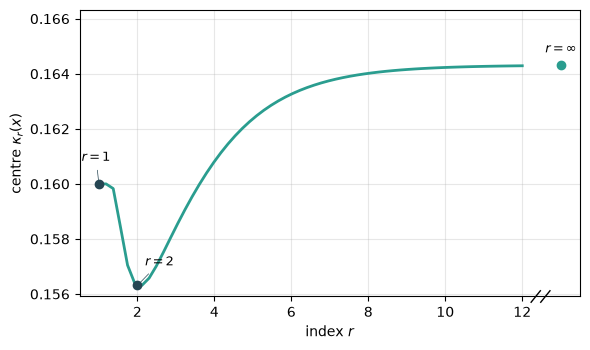

In [6]:
rg = np.linspace(1, 12, 60)
kg = [float(np.exp(centre(np.log(PH5), float(r)))) for r in rg]
kinf = float(np.exp(centre(np.log(PH5), np.inf)))
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(rg, kg, color='#2a9d8f', lw=2)
xinf = 13.0
ax.plot(xinf, kinf, 'o', color='#2a9d8f')
ax.annotate(r'$r=\infty$', (xinf, kinf), textcoords='offset points', xytext=(0, 7),
            ha='center', va='bottom', fontsize=9)
# axis break between the finite r-range and the r=inf point
brk = dict(transform=ax.get_xaxis_transform(), color='k', clip_on=False, lw=1)
for x0 in (12.35, 12.6):
    ax.plot([x0 - 0.12, x0 + 0.12], [-0.02, 0.02], **brk)
ax.set_xlim(0.5, xinf + 0.5)
# r labels placed clearly off the curve, with a thin connector to the point
for r0, xo, dy in [(1, -2, 16), (2, 16, 14)]:
    k0 = float(np.exp(centre(np.log(PH5), r0)))
    ax.plot(r0, k0, 'o', color='#264653')
    ax.annotate(f'$r={r0}$', (r0, k0), textcoords='offset points', xytext=(xo, dy),
                ha='center', fontsize=9,
                arrowprops=dict(arrowstyle='-', lw=0.5, color='#264653'))
ax.set_xlabel('index $r$'); ax.set_ylabel(r'centre $\kappa_r(x)$')
ax.grid(alpha=.3)
ax.set_ylim(top=kinf + 0.0020)   # headroom so the r=inf label stays inside the frame
fig.tight_layout(); fig.savefig(paths.figure('kappa_nonmonotone.pdf'), bbox_inches='tight')
plt.show()